#ML Assignment 2 - Dry Bean Classification
##Objective
The objective of this project is to build and compare machine learning classification models for predicting dry bean varieties using morphological features.

##Classification Models
The following five algorithms are evaluated:

Logistic Regression



1.   Logistic Regression
2.   Decision Tree
3.   K-Nearest Neighbors (KNN)
4.   Gaussian Naive Bayes
5.   Support Vector Machine (SVM)

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Train/test splitting and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Saving trained models
import joblib

print("All libraries imported successfully!")

All libraries imported successfully!





##Dataset Loading and Exploration
The Dry Bean Dataset is used for this classification problem. The dataset contains morphological measurements of different dry bean varieties.

In [4]:
# Load the Dry Bean dataset
file_path = "/content/Dry_Bean_Dataset.xlsx"

bean_data = pd.read_excel(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
# Display the first five rows
bean_data.head()


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [7]:
#dataset dimensions
print("Number of rows:", bean_data.shape[0])
print("Number of columns:", bean_data.shape[1])

Number of rows: 13611
Number of columns: 17


In [12]:
#Print column names
print("Column names:")
for column in bean_data.columns:
    print(column)

Column names:
Area
Perimeter
MajorAxisLength
MinorAxisLength
AspectRation
Eccentricity
ConvexArea
EquivDiameter
Extent
Solidity
roundness
Compactness
ShapeFactor1
ShapeFactor2
ShapeFactor3
ShapeFactor4
Class


In [13]:
#checking target classes
print("Bean classes:")
print(bean_data["Class"].unique())

print("\nNumber of classes:")
print(bean_data["Class"].nunique())

Bean classes:
['SEKER' 'BARBUNYA' 'BOMBAY' 'CALI' 'HOROZ' 'SIRA' 'DERMASON']

Number of classes:
7


In [14]:
#checking missing values
print("Missing values in each column:")
print(bean_data.isnull().sum())

Missing values in each column:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64


In [11]:
print("\nTotal missing values:", bean_data.isnull().sum().sum())


Total missing values: 0


In [15]:
#check duplicates
duplicate_count = bean_data.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 68


#Handling Duplicate records
The dataset was checked for duplicate observations. Duplicate records were removed before splitting the data into training and testing sets to avoid repeated observations influencing model evaluation.

In [18]:
# Remove duplicate rows
bean_data = bean_data.drop_duplicates().reset_index(drop=True)

print("Duplicate rows after removal:", bean_data.duplicated().sum())
print("Dataset shape after removing duplicates:", bean_data.shape)

Duplicate rows after removal: 0
Dataset shape after removing duplicates: (13543, 17)


#Dataset Structure and Class Distribution
After removing duplicate records, the structure, data types, and distribution of the target classes were examined before model development.

In [19]:
# Display dataset information
bean_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13543 entries, 0 to 13542
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13543 non-null  int64  
 1   Perimeter        13543 non-null  float64
 2   MajorAxisLength  13543 non-null  float64
 3   MinorAxisLength  13543 non-null  float64
 4   AspectRation     13543 non-null  float64
 5   Eccentricity     13543 non-null  float64
 6   ConvexArea       13543 non-null  int64  
 7   EquivDiameter    13543 non-null  float64
 8   Extent           13543 non-null  float64
 9   Solidity         13543 non-null  float64
 10  roundness        13543 non-null  float64
 11  Compactness      13543 non-null  float64
 12  ShapeFactor1     13543 non-null  float64
 13  ShapeFactor2     13543 non-null  float64
 14  ShapeFactor3     13543 non-null  float64
 15  ShapeFactor4     13543 non-null  float64
 16  Class            13543 non-null  object 
dtypes: float64(1

In [20]:
# Count observations belonging to each bean class
class_distribution = bean_data["Class"].value_counts()

print("Class distribution:")
print(class_distribution)

Class distribution:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


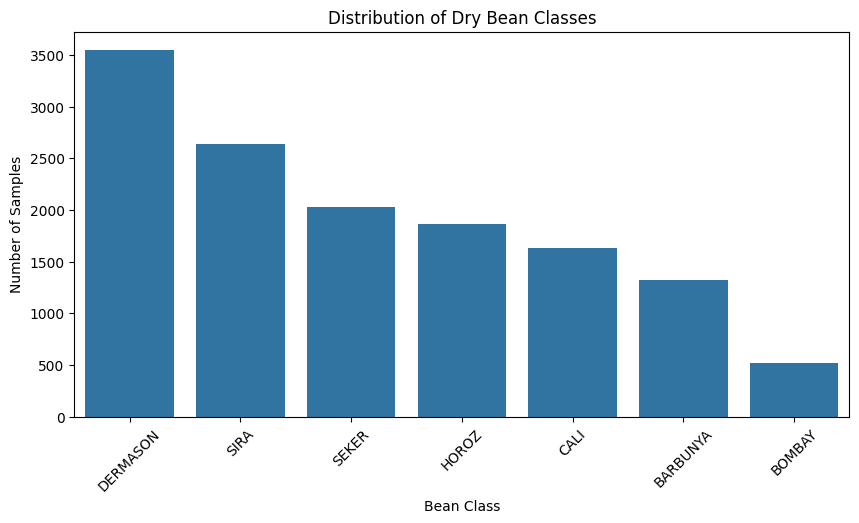

In [21]:
#Visualise the data distribution
plt.figure(figsize=(10, 5))

sns.countplot(
    data=bean_data,
    x="Class",
    order=bean_data["Class"].value_counts().index
)

plt.title("Distribution of Dry Bean Classes")
plt.xlabel("Bean Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)

plt.show()

In [22]:
# Statistical summary of numerical features
bean_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Area,13543.0,53048.460385,29392.438324,20420.000000,36282.500000,44580.000000,61382.000000,254616.000000
Perimeter,13543.0,854.993406,214.722684,524.736000,703.230000,793.896000,977.146500,1985.370000
MajorAxisLength,13543.0,319.895602,85.809260,183.601165,253.086806,296.404589,376.312489,738.860153
MinorAxisLength,13543.0,202.365321,45.051632,122.512653,175.886357,192.491117,217.245403,460.198497
AspectRation,13543.0,1.581075,0.245245,1.024868,1.430662,1.549860,1.703916,2.430306
Eccentricity,13543.0,0.750315,0.091858,0.218951,0.715144,0.763997,0.809671,0.911423
ConvexArea,13543.0,53767.986709,29844.248525,20684.000000,36673.000000,45122.000000,62360.000000,263261.000000
EquivDiameter,13543.0,253.034094,59.307709,161.243764,214.933277,238.245711,279.560351,569.374358
Extent,13543.0,0.749829,0.048939,0.555315,0.718735,0.759903,0.786849,0.866195
Solidity,13543.0,0.987152,0.004650,0.919246,0.985678,0.988288,0.990019,0.994677


#Feature and Target Separation
The Class column represents the target variable. All remaining columns are used as input features for classification.

In [23]:
# Separate input features and target
X = bean_data.drop(columns=["Class"])
y = bean_data["Class"]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nNumber of input features:", X.shape[1])
print("Number of target classes:", y.nunique())

Feature matrix shape: (13543, 16)
Target vector shape: (13543,)

Number of input features: 16
Number of target classes: 7


#Train - Test Data Split
The cleaned dataset is divided into training and testing sets using an 80:20 ratio. Stratified sampling is used to maintain the distribution of the seven bean classes in both sets. A fixed random state is used to make the split reproducible.

In [24]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (10834, 16)
Testing feature shape: (2709, 16)
Training target shape: (10834,)
Testing target shape: (2709,)


#Model Training and Evaluation
##1. Logistic Regression
Logistic Regression is trained using a pipeline containing StandardScaler for feature scaling followed by the Logistic Regression classifier.

In [25]:
# Create Logistic Regression pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [26]:
# Predict classes for the test data
y_pred_logistic = logistic_model.predict(X_test)

# Predict class probabilities for AUC calculation
y_prob_logistic = logistic_model.predict_proba(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [27]:
# Calculate Logistic Regression evaluation metrics
log_accuracy = accuracy_score(y_test, y_pred_logistic)

log_precision = precision_score(
    y_test,
    y_pred_logistic,
    average="weighted"
)

log_recall = recall_score(
    y_test,
    y_pred_logistic,
    average="weighted"
)

log_f1 = f1_score(
    y_test,
    y_pred_logistic,
    average="weighted"
)

log_mcc = matthews_corrcoef(
    y_test,
    y_pred_logistic
)

log_auc = roc_auc_score(
    y_test,
    y_prob_logistic,
    multi_class="ovr",
    average="weighted",
    labels=logistic_model.classes_
)

print("Logistic Regression Results")
print("---------------------------")
print(f"Accuracy  : {log_accuracy:.4f}")
print(f"AUC       : {log_auc:.4f}")
print(f"Precision : {log_precision:.4f}")
print(f"Recall    : {log_recall:.4f}")
print(f"F1 Score  : {log_f1:.4f}")
print(f"MCC       : {log_mcc:.4f}")

Logistic Regression Results
---------------------------
Accuracy  : 0.9192
AUC       : 0.9934
Precision : 0.9197
Recall    : 0.9192
F1 Score  : 0.9193
MCC       : 0.9023


#Confusion Matrix - Logistic Regression
The confusion Matrix shows relation between the actual bean classes and the classes predicted by the Logistic Regression model.

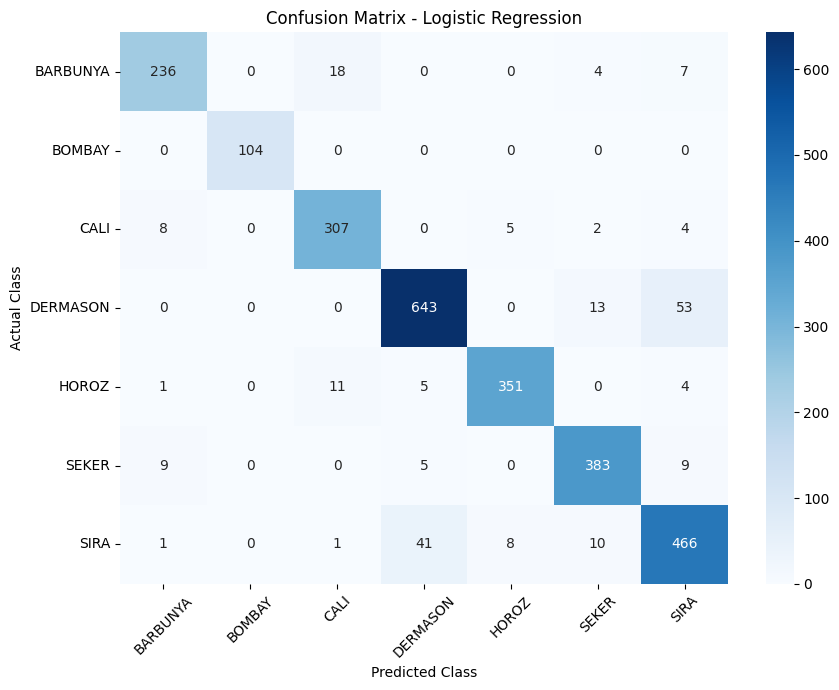

In [28]:
# Generate confusion matrix
cm_logistic = confusion_matrix(y_test, y_pred_logistic)

# Display confusion matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=logistic_model.classes_,
    yticklabels=logistic_model.classes_
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [29]:
# Display detailed classification report
print("Classification Report - Logistic Regression")
print("-------------------------------------------")
print(classification_report(y_test, y_pred_logistic))

Classification Report - Logistic Regression
-------------------------------------------
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.94      0.93       326
    DERMASON       0.93      0.91      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.94      0.94       406
        SIRA       0.86      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



In [30]:
# Store Logistic Regression results
model_results = []

model_results.append({
    "Model": "Logistic Regression",
    "Accuracy": log_accuracy,
    "AUC": log_auc,
    "Precision": log_precision,
    "Recall": log_recall,
    "F1 Score": log_f1,
    "MCC": log_mcc
})

pd.DataFrame(model_results).round(4)

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023


#2. Decision Tree Classifier
A Decision Tree classifier is trained using the same training data. Unlike distance-based and linear models, feature scaling is not required for a Decision Tree.

In [31]:
# Create Decision Tree classifier
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [32]:
# Predict classes for the test data
y_pred_tree = decision_tree_model.predict(X_test)

# Predict class probabilities for AUC calculation
y_prob_tree = decision_tree_model.predict_proba(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [33]:
# Calculate Decision Tree evaluation metrics
tree_accuracy = accuracy_score(y_test, y_pred_tree)

tree_precision = precision_score(
    y_test,
    y_pred_tree,
    average="weighted"
)

tree_recall = recall_score(
    y_test,
    y_pred_tree,
    average="weighted"
)

tree_f1 = f1_score(
    y_test,
    y_pred_tree,
    average="weighted"
)

tree_mcc = matthews_corrcoef(
    y_test,
    y_pred_tree
)

tree_auc = roc_auc_score(
    y_test,
    y_prob_tree,
    multi_class="ovr",
    average="weighted",
    labels=decision_tree_model.classes_
)

print("Decision Tree Results")
print("---------------------")
print(f"Accuracy  : {tree_accuracy:.4f}")
print(f"AUC       : {tree_auc:.4f}")
print(f"Precision : {tree_precision:.4f}")
print(f"Recall    : {tree_recall:.4f}")
print(f"F1 Score  : {tree_f1:.4f}")
print(f"MCC       : {tree_mcc:.4f}")

Decision Tree Results
---------------------
Accuracy  : 0.8966
AUC       : 0.9363
Precision : 0.8965
Recall    : 0.8966
F1 Score  : 0.8964
MCC       : 0.8750


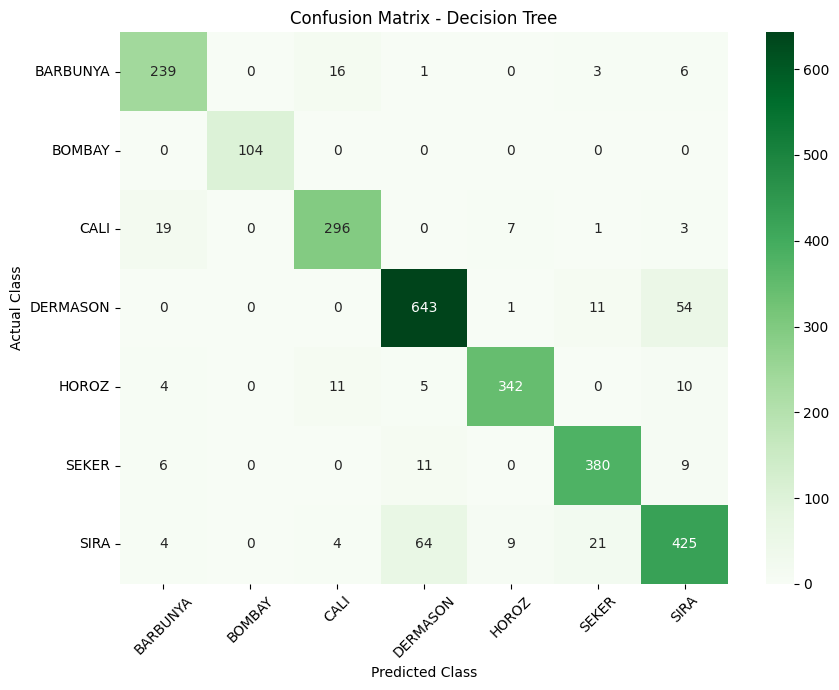

In [34]:
# Generate Decision Tree confusion matrix
cm_tree = confusion_matrix(y_test, y_pred_tree)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=decision_tree_model.classes_,
    yticklabels=decision_tree_model.classes_
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [35]:
print("Classification Report - Decision Tree")
print("-------------------------------------")
print(classification_report(y_test, y_pred_tree))

Classification Report - Decision Tree
-------------------------------------
              precision    recall  f1-score   support

    BARBUNYA       0.88      0.90      0.89       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.91      0.91       326
    DERMASON       0.89      0.91      0.90       709
       HOROZ       0.95      0.92      0.94       372
       SEKER       0.91      0.94      0.92       406
        SIRA       0.84      0.81      0.82       527

    accuracy                           0.90      2709
   macro avg       0.91      0.91      0.91      2709
weighted avg       0.90      0.90      0.90      2709



In [36]:
model_results.append({
    "Model": "Decision Tree",
    "Accuracy": tree_accuracy,
    "AUC": tree_auc,
    "Precision": tree_precision,
    "Recall": tree_recall,
    "F1 Score": tree_f1,
    "MCC": tree_mcc
})

results_df = pd.DataFrame(model_results)

results_df.round(4)

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
1,Decision Tree,0.8966,0.9363,0.8965,0.8966,0.8964,0.8750


#3. K-Nearest Neighbors (KNN)
K-Nearest Neighbors classifies a sample based on the classes of nearby training samples. Since KNN relies on distance calculations, feature scaling is applied using StandardScaler.

In [37]:
# Create KNN pipeline with feature scaling
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

# Train the model
knn_model.fit(X_train, y_train)

print("KNN trained successfully!")

KNN trained successfully!


In [38]:
# Predict classes for the test data
y_pred_knn = knn_model.predict(X_test)

# Predict class probabilities for AUC calculation
y_prob_knn = knn_model.predict_proba(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [39]:
# Calculate KNN evaluation metrics
knn_accuracy = accuracy_score(y_test, y_pred_knn)

knn_precision = precision_score(
    y_test,
    y_pred_knn,
    average="weighted"
)

knn_recall = recall_score(
    y_test,
    y_pred_knn,
    average="weighted"
)

knn_f1 = f1_score(
    y_test,
    y_pred_knn,
    average="weighted"
)

knn_mcc = matthews_corrcoef(
    y_test,
    y_pred_knn
)

knn_auc = roc_auc_score(
    y_test,
    y_prob_knn,
    multi_class="ovr",
    average="weighted",
    labels=knn_model.classes_
)

print("KNN Results")
print("-----------")
print(f"Accuracy  : {knn_accuracy:.4f}")
print(f"AUC       : {knn_auc:.4f}")
print(f"Precision : {knn_precision:.4f}")
print(f"Recall    : {knn_recall:.4f}")
print(f"F1 Score  : {knn_f1:.4f}")
print(f"MCC       : {knn_mcc:.4f}")

KNN Results
-----------
Accuracy  : 0.9155
AUC       : 0.9811
Precision : 0.9163
Recall    : 0.9155
F1 Score  : 0.9157
MCC       : 0.8978


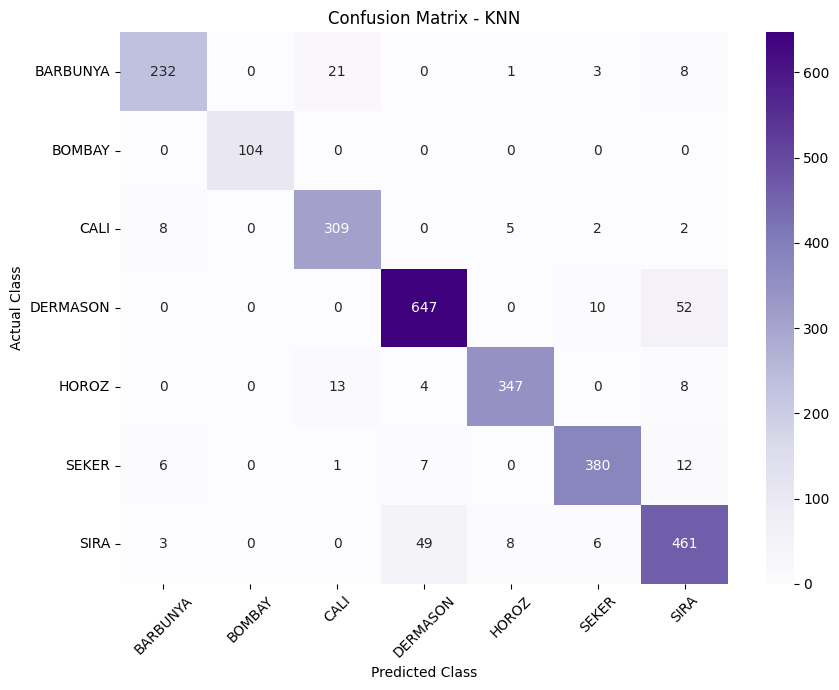

In [40]:
# Generate KNN confusion matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=knn_model.classes_,
    yticklabels=knn_model.classes_
)

plt.title("Confusion Matrix - KNN")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


In [41]:
print("Classification Report - KNN")
print("---------------------------")
print(classification_report(y_test, y_pred_knn))

Classification Report - KNN
---------------------------
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.88      0.90       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.90      0.95      0.92       326
    DERMASON       0.92      0.91      0.91       709
       HOROZ       0.96      0.93      0.95       372
       SEKER       0.95      0.94      0.94       406
        SIRA       0.85      0.87      0.86       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



In [42]:
model_results.append({
    "Model": "K-Nearest Neighbors",
    "Accuracy": knn_accuracy,
    "AUC": knn_auc,
    "Precision": knn_precision,
    "Recall": knn_recall,
    "F1 Score": knn_f1,
    "MCC": knn_mcc
})

results_df = pd.DataFrame(model_results)

results_df.round(4)

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
1,Decision Tree,0.8966,0.9363,0.8965,0.8966,0.8964,0.8750
2,K-Nearest Neighbors,0.9155,0.9811,0.9163,0.9155,0.9157,0.8978


#4. Gaussian Naive Bayes
Gaussian Naive Bayes is a probabilistic classification algorithm based on Bayes' theorem. It assumes that the numerical features follow a Gaussian distribution within each clas

In [43]:
# Create Gaussian Naive Bayes classifier
naive_bayes_model = GaussianNB()

# Train the model
naive_bayes_model.fit(X_train, y_train)

print("Gaussian Naive Bayes trained successfully!")

Gaussian Naive Bayes trained successfully!


In [44]:
# Predict classes for the test data
y_pred_nb = naive_bayes_model.predict(X_test)

# Predict class probabilities for AUC calculation
y_prob_nb = naive_bayes_model.predict_proba(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [45]:
# Calculate Gaussian Naive Bayes evaluation metrics
nb_accuracy = accuracy_score(y_test, y_pred_nb)

nb_precision = precision_score(
    y_test,
    y_pred_nb,
    average="weighted"
)

nb_recall = recall_score(
    y_test,
    y_pred_nb,
    average="weighted"
)

nb_f1 = f1_score(
    y_test,
    y_pred_nb,
    average="weighted"
)

nb_mcc = matthews_corrcoef(
    y_test,
    y_pred_nb
)

nb_auc = roc_auc_score(
    y_test,
    y_prob_nb,
    multi_class="ovr",
    average="weighted",
    labels=naive_bayes_model.classes_
)

print("Gaussian Naive Bayes Results")
print("----------------------------")
print(f"Accuracy  : {nb_accuracy:.4f}")
print(f"AUC       : {nb_auc:.4f}")
print(f"Precision : {nb_precision:.4f}")
print(f"Recall    : {nb_recall:.4f}")
print(f"F1 Score  : {nb_f1:.4f}")
print(f"MCC       : {nb_mcc:.4f}")


Gaussian Naive Bayes Results
----------------------------
Accuracy  : 0.7630
AUC       : 0.9644
Precision : 0.7647
Recall    : 0.7630
F1 Score  : 0.7607
MCC       : 0.7143


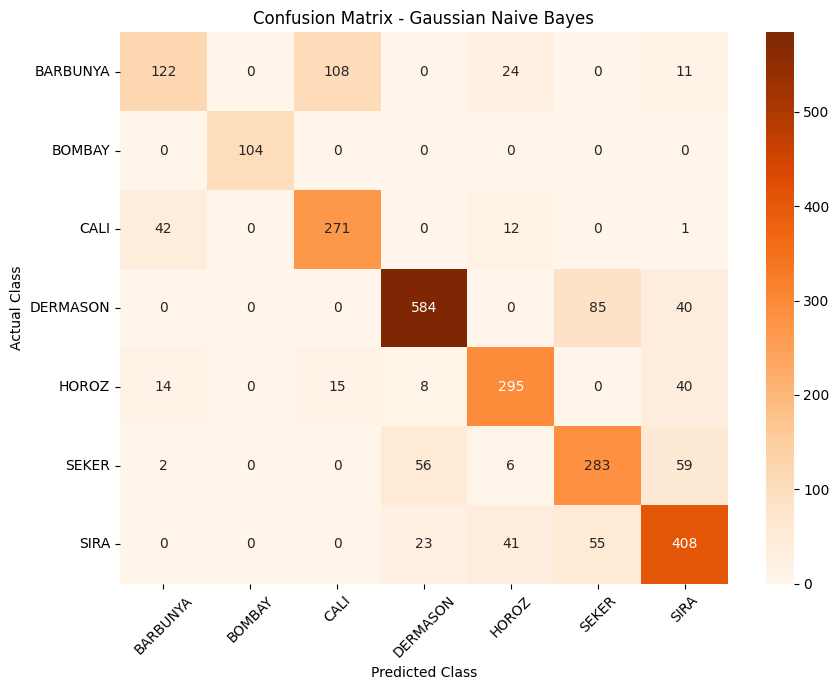

In [46]:
# Generate Naive Bayes confusion matrix
cm_nb = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=naive_bayes_model.classes_,
    yticklabels=naive_bayes_model.classes_
)

plt.title("Confusion Matrix - Gaussian Naive Bayes")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [47]:
print("Classification Report - Gaussian Naive Bayes")
print("---------------------------------------------")
print(classification_report(y_test, y_pred_nb))

Classification Report - Gaussian Naive Bayes
---------------------------------------------
              precision    recall  f1-score   support

    BARBUNYA       0.68      0.46      0.55       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.69      0.83      0.75       326
    DERMASON       0.87      0.82      0.85       709
       HOROZ       0.78      0.79      0.79       372
       SEKER       0.67      0.70      0.68       406
        SIRA       0.73      0.77      0.75       527

    accuracy                           0.76      2709
   macro avg       0.77      0.77      0.77      2709
weighted avg       0.76      0.76      0.76      2709



In [48]:
model_results.append({
    "Model": "Gaussian Naive Bayes",
    "Accuracy": nb_accuracy,
    "AUC": nb_auc,
    "Precision": nb_precision,
    "Recall": nb_recall,
    "F1 Score": nb_f1,
    "MCC": nb_mcc
})

results_df = pd.DataFrame(model_results)

results_df.round(4)

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
1,Decision Tree,0.8966,0.9363,0.8965,0.8966,0.8964,0.8750
2,K-Nearest Neighbors,0.9155,0.9811,0.9163,0.9155,0.9157,0.8978
3,Gaussian Naive Bayes,0.7630,0.9644,0.7647,0.7630,0.7607,0.7143


#5. Support Vector Machine (SVM)
Support Vector Machine is used for multiclass classification using the RBF kernel. Feature scaling is applied using StandardScaler because SVM is sensitive to differences in feature scales. Probability estimation is enabled to calculate the multiclass AUC score.

In [49]:
# Create SVM pipeline with feature scaling
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ))
])

# Train the model
svm_model.fit(X_train, y_train)

print("SVM trained successfully!")

SVM trained successfully!


In [50]:
# Predict classes for the test data
y_pred_svm = svm_model.predict(X_test)

# Predict class probabilities for AUC calculation
y_prob_svm = svm_model.predict_proba(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [51]:
# Calculate SVM evaluation metrics
svm_accuracy = accuracy_score(y_test, y_pred_svm)

svm_precision = precision_score(
    y_test,
    y_pred_svm,
    average="weighted"
)

svm_recall = recall_score(
    y_test,
    y_pred_svm,
    average="weighted"
)

svm_f1 = f1_score(
    y_test,
    y_pred_svm,
    average="weighted"
)

svm_mcc = matthews_corrcoef(
    y_test,
    y_pred_svm
)

svm_auc = roc_auc_score(
    y_test,
    y_prob_svm,
    multi_class="ovr",
    average="weighted",
    labels=svm_model.classes_
)

print("SVM Results")
print("-----------")
print(f"Accuracy  : {svm_accuracy:.4f}")
print(f"AUC       : {svm_auc:.4f}")
print(f"Precision : {svm_precision:.4f}")
print(f"Recall    : {svm_recall:.4f}")
print(f"F1 Score  : {svm_f1:.4f}")
print(f"MCC       : {svm_mcc:.4f}")

SVM Results
-----------
Accuracy  : 0.9210
AUC       : 0.9933
Precision : 0.9214
Recall    : 0.9210
F1 Score  : 0.9211
MCC       : 0.9045


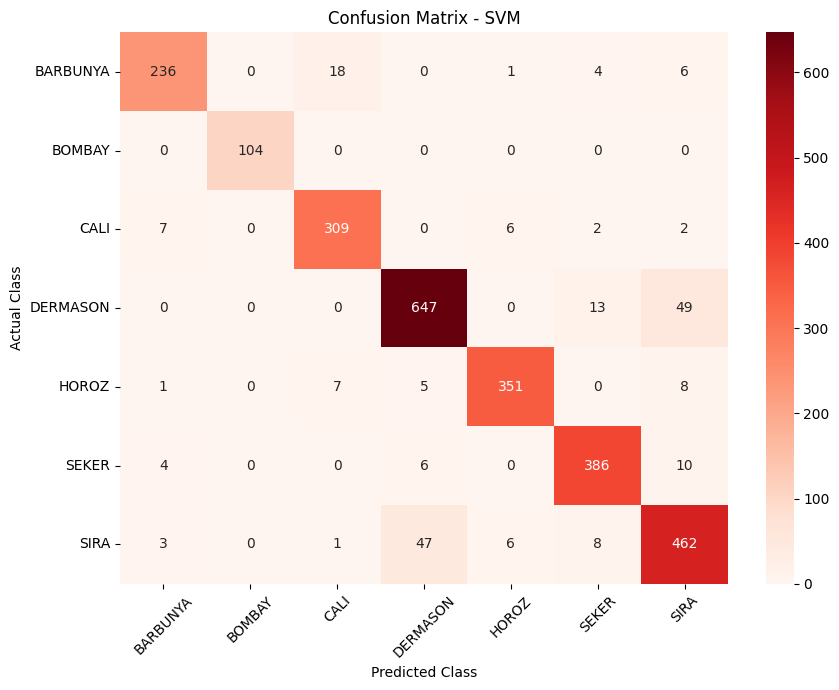

In [52]:
# Generate SVM confusion matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Reds",
    xticklabels=svm_model.classes_,
    yticklabels=svm_model.classes_
)

plt.title("Confusion Matrix - SVM")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [53]:
print("Classification Report - SVM")
print("---------------------------")
print(classification_report(y_test, y_pred_svm))

Classification Report - SVM
---------------------------
              precision    recall  f1-score   support

    BARBUNYA       0.94      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.95      0.93       326
    DERMASON       0.92      0.91      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.95      0.94       406
        SIRA       0.86      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



In [54]:
model_results.append({
    "Model": "Support Vector Machine",
    "Accuracy": svm_accuracy,
    "AUC": svm_auc,
    "Precision": svm_precision,
    "Recall": svm_recall,
    "F1 Score": svm_f1,
    "MCC": svm_mcc
})

results_df = pd.DataFrame(model_results)

results_df.round(4)

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
1,Decision Tree,0.8966,0.9363,0.8965,0.8966,0.8964,0.8750
2,K-Nearest Neighbors,0.9155,0.9811,0.9163,0.9155,0.9157,0.8978
3,Gaussian Naive Bayes,0.7630,0.9644,0.7647,0.7630,0.7607,0.7143
4,Support Vector Machine,0.9210,0.9933,0.9214,0.9210,0.9211,0.9045


#Saving Trained model
The five trained classification models are saved using Joblib. These saved models can later be loaded by the Streamlit application for prediction and evaluation without retraining.

In [55]:
# Create a folder for saved models
import os

os.makedirs("model", exist_ok=True)

# Save all five trained models
joblib.dump(logistic_model, "model/logistic_regression.joblib")
joblib.dump(decision_tree_model, "model/decision_tree.joblib")
joblib.dump(knn_model, "model/knn.joblib")
joblib.dump(naive_bayes_model, "model/naive_bayes.joblib")
joblib.dump(svm_model, "model/svm.joblib")

print("All five trained models saved successfully!")

All five trained models saved successfully!


In [56]:
# Check the saved model files
print("Saved model files:")

for file_name in os.listdir("model"):
    print(file_name)

Saved model files:
knn.joblib
svm.joblib
naive_bayes.joblib
logistic_regression.joblib
decision_tree.joblib


#Exporting Test Data
The test portion of the original train-test split is exported as a CSV file. The file contains the 16 input features and the actual Class column so that the saved models can be evaluated using the Streamlit application.

In [57]:
# Create test dataset containing features and actual target class
test_data = X_test.copy()

test_data["Class"] = y_test

# Save as CSV
test_data.to_csv("test_data.csv", index=False)

print("test_data.csv created successfully!")
print("Test data shape:", test_data.shape)

test_data.csv created successfully!
Test data shape: (2709, 17)


In [58]:
test_data.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
1223,40512,737.636,248.202030,208.525152,1.190274,0.542365,40973,227.115566,0.744268,0.988749,0.935641,0.915043,0.006127,0.002650,0.837304,0.996621,SEKER
11769,31890,660.655,250.417300,162.522502,1.540816,0.760783,32240,201.503372,0.801962,0.989144,0.918153,0.804670,0.007853,0.002031,0.647494,0.997670,DERMASON
12059,33107,671.869,244.728317,172.938116,1.415121,0.707560,33506,205.312303,0.798683,0.988092,0.921638,0.838940,0.007392,0.002259,0.703820,0.995990,DERMASON
7126,61684,984.878,412.115648,191.473280,2.152340,0.885515,62303,280.247227,0.784724,0.990065,0.799130,0.680021,0.006681,0.000881,0.462428,0.995303,HOROZ
638,37189,700.253,243.343401,194.910062,1.248491,0.598708,37534,217.601713,0.784826,0.990808,0.953047,0.894217,0.006543,0.002581,0.799623,0.998322,SEKER


In [59]:
print("Rows:", test_data.shape[0])
print("Columns:", test_data.shape[1])
print("Missing values:", test_data.isnull().sum().sum())

Rows: 2709
Columns: 17
Missing values: 0


In [60]:
# Load the saved Logistic Regression model
loaded_logistic_model = joblib.load(
    "model/logistic_regression.joblib"
)

# Separate test features
test_features = test_data.drop(columns=["Class"])

# Predict using the SAVED model
loaded_predictions = loaded_logistic_model.predict(test_features)

# Check accuracy
loaded_model_accuracy = accuracy_score(
    test_data["Class"],
    loaded_predictions
)

print(f"Loaded model accuracy: {loaded_model_accuracy:.4f}")

Loaded model accuracy: 0.9192


#Streamlit Application
A Streamlit web application is created to allow users to upload a CSV test dataset, select one of the five trained classification models, and evaluate the selected saved model without retraining.

In [61]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ---------------------------------------------------------
# Page configuration
# ---------------------------------------------------------
st.set_page_config(
    page_title="Dry Bean Classification",
    page_icon="🌱",
    layout="wide"
)

st.title("🌱 Dry Bean Classification Explorer")

st.write(
    """
    This application compares five machine learning classification models
    trained on the Dry Bean Dataset.

    Upload a test CSV file, select a trained model, and view its
    classification performance.
    """
)

# ---------------------------------------------------------
# Available trained models
# ---------------------------------------------------------
model_files = {
    "Logistic Regression": "model/logistic_regression.joblib",
    "Decision Tree": "model/decision_tree.joblib",
    "K-Nearest Neighbors": "model/knn.joblib",
    "Gaussian Naive Bayes": "model/naive_bayes.joblib",
    "Support Vector Machine": "model/svm.joblib"
}

# ---------------------------------------------------------
# Model selection
# ---------------------------------------------------------
selected_model_name = st.selectbox(
    "Select a classification model",
    list(model_files.keys())
)

# ---------------------------------------------------------
# CSV upload
# ---------------------------------------------------------
uploaded_file = st.file_uploader(
    "Upload test CSV file",
    type=["csv"]
)

if uploaded_file is not None:

    # Read uploaded dataset
    test_data = pd.read_csv(uploaded_file)

    st.subheader("Uploaded Dataset Preview")
    st.dataframe(test_data.head())

    # Check for target column
    if "Class" not in test_data.columns:
        st.error(
            "The uploaded CSV must contain a 'Class' column."
        )

    else:

        # Separate features and actual class
        X_uploaded = test_data.drop(columns=["Class"])
        y_actual = test_data["Class"]

        try:
            # -------------------------------------------------
            # Load SAVED model
            # -------------------------------------------------
            model = joblib.load(
                model_files[selected_model_name]
            )

            # -------------------------------------------------
            # Predictions
            # -------------------------------------------------
            y_pred = model.predict(X_uploaded)
            y_prob = model.predict_proba(X_uploaded)

            # -------------------------------------------------
            # Evaluation metrics
            # -------------------------------------------------
            accuracy = accuracy_score(
                y_actual,
                y_pred
            )

            precision = precision_score(
                y_actual,
                y_pred,
                average="weighted",
                zero_division=0
            )

            recall = recall_score(
                y_actual,
                y_pred,
                average="weighted",
                zero_division=0
            )

            f1 = f1_score(
                y_actual,
                y_pred,
                average="weighted",
                zero_division=0
            )

            mcc = matthews_corrcoef(
                y_actual,
                y_pred
            )

            auc = roc_auc_score(
                y_actual,
                y_prob,
                multi_class="ovr",
                average="weighted",
                labels=model.classes_
            )

            # -------------------------------------------------
            # Display metrics
            # -------------------------------------------------
            st.subheader(
                f"Evaluation Results - {selected_model_name}"
            )

            col1, col2, col3 = st.columns(3)

            col1.metric(
                "Accuracy",
                f"{accuracy:.4f}"
            )

            col2.metric(
                "AUC",
                f"{auc:.4f}"
            )

            col3.metric(
                "Precision",
                f"{precision:.4f}"
            )

            col4, col5, col6 = st.columns(3)

            col4.metric(
                "Recall",
                f"{recall:.4f}"
            )

            col5.metric(
                "F1 Score",
                f"{f1:.4f}"
            )

            col6.metric(
                "MCC",
                f"{mcc:.4f}"
            )

            # -------------------------------------------------
            # Confusion matrix
            # -------------------------------------------------
            st.subheader("Confusion Matrix")

            cm = confusion_matrix(
                y_actual,
                y_pred,
                labels=model.classes_
            )

            fig, ax = plt.subplots(
                figsize=(9, 7)
            )

            sns.heatmap(
                cm,
                annot=True,
                fmt="d",
                cmap="Blues",
                xticklabels=model.classes_,
                yticklabels=model.classes_,
                ax=ax
            )

            ax.set_xlabel("Predicted Class")
            ax.set_ylabel("Actual Class")
            ax.set_title(
                f"Confusion Matrix - {selected_model_name}"
            )

            plt.xticks(rotation=45)
            plt.yticks(rotation=0)

            plt.tight_layout()

            st.pyplot(fig)

            # -------------------------------------------------
            # Classification report
            # -------------------------------------------------
            st.subheader("Classification Report")

            report = classification_report(
                y_actual,
                y_pred,
                output_dict=True,
                zero_division=0
            )

            report_df = pd.DataFrame(
                report
            ).transpose()

            st.dataframe(
                report_df.round(4)
            )

        except Exception as error:

            st.error(
                f"Unable to evaluate the model: {error}"
            )

else:

    st.info(
        "Upload test_data.csv to begin model evaluation."
    )

Writing app.py


In [62]:
# Verify that app.py was created
import os

print("app.py exists:", os.path.exists("app.py"))
print("test_data.csv exists:", os.path.exists("test_data.csv"))

print("\nSaved models:")

for file_name in os.listdir("model"):
    print("-", file_name)

app.py exists: True
test_data.csv exists: True

Saved models:
- knn.joblib
- svm.joblib
- naive_bayes.joblib
- logistic_regression.joblib
- decision_tree.joblib


In [63]:
%%writefile requirements.txt

streamlit
pandas
scikit-learn
joblib
matplotlib
seaborn

Writing requirements.txt


In [64]:
!cat requirements.txt


streamlit
pandas
scikit-learn
joblib
matplotlib
seaborn


In [65]:
#Check all required project files
import os

print("PROJECT FILE CHECK")
print("------------------")

required_files = [
    "app.py",
    "requirements.txt",
    "test_data.csv",
    "model/logistic_regression.joblib",
    "model/decision_tree.joblib",
    "model/knn.joblib",
    "model/naive_bayes.joblib",
    "model/svm.joblib"
]

all_files_present = True

for file in required_files:
    if os.path.exists(file):
        print(f"✓ {file}")
    else:
        print(f"✗ MISSING: {file}")
        all_files_present = False

if all_files_present:
    print("\nAll required project files are present!")
else:
    print("\nSome project files are missing.")

PROJECT FILE CHECK
------------------
✓ app.py
✓ requirements.txt
✓ test_data.csv
✓ model/logistic_regression.joblib
✓ model/decision_tree.joblib
✓ model/knn.joblib
✓ model/naive_bayes.joblib
✓ model/svm.joblib

All required project files are present!


In [66]:
#Check that all five saved models load
model_paths = {
    "Logistic Regression": "model/logistic_regression.joblib",
    "Decision Tree": "model/decision_tree.joblib",
    "K-Nearest Neighbors": "model/knn.joblib",
    "Gaussian Naive Bayes": "model/naive_bayes.joblib",
    "Support Vector Machine": "model/svm.joblib"
}

for model_name, model_path in model_paths.items():

    loaded_model = joblib.load(model_path)

    predictions = loaded_model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    print(f"{model_name}: loaded successfully - Accuracy = {accuracy:.4f}")

Logistic Regression: loaded successfully - Accuracy = 0.9192
Decision Tree: loaded successfully - Accuracy = 0.8966
K-Nearest Neighbors: loaded successfully - Accuracy = 0.9155
Gaussian Naive Bayes: loaded successfully - Accuracy = 0.7630
Support Vector Machine: loaded successfully - Accuracy = 0.9210


In [67]:
#Download all the project files
!zip -r model.zip model


  adding: model/ (stored 0%)
  adding: model/knn.joblib (deflated 9%)
  adding: model/svm.joblib (deflated 42%)
  adding: model/naive_bayes.joblib (deflated 22%)
  adding: model/logistic_regression.joblib (deflated 27%)
  adding: model/decision_tree.joblib (deflated 85%)
